# Perceptrón Multicapa (MLP)

## ¿Cuál es el objetivo de un MLP?

El **Perceptrón Multicapa** (Multilayer Perceptron, MLP) es la extensión natural del Perceptrón simple. Mientras que el Perceptrón tiene **una sola neurona** y solo puede resolver problemas linealmente separables, el MLP apila **múltiples capas de neuronas** con funciones de activación no lineales, lo que le permite aprender **fronteras de decisión complejas** y resolver problemas como XOR.

El MLP es la red neuronal **fully-connected** (completamente conectada) más básica y la base sobre la que se construyen arquitecturas más avanzadas (CNN, RNN, Transformers).

Formalmente, un MLP con $L$ capas calcula:

$$
\mathbf{a}^{[0]} = \mathbf{x}
$$

$$
\mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]} \quad \text{para } l = 1, \dots, L
$$

$$
\mathbf{a}^{[l]} = f^{[l]}(\mathbf{z}^{[l]}) \quad \text{para } l = 1, \dots, L
$$

$$
\hat{\mathbf{y}} = \mathbf{a}^{[L]}
$$

Donde:
- $\mathbf{W}^{[l]}$: matriz de pesos de la capa $l$ (dimensión: $n^{[l]} \times n^{[l-1]}$)
- $\mathbf{b}^{[l]}$: vector de sesgos de la capa $l$
- $f^{[l]}$: función de activación de la capa $l$ (ReLU para ocultas, softmax para salida)
- $n^{[l]}$: número de neuronas en la capa $l$

**¿Por qué funciona?** El **Teorema de Aproximación Universal** garantiza que un MLP con suficientes neuronas en una capa oculta puede aproximar cualquier función continua.

**Supongamos un conjunto de datos simple**

Consideremos el clásico problema **XOR**, que un Perceptrón simple no puede resolver:

| $x_1$ | $x_2$ | $y$ |
|-------|-------|-----|
| 0     | 0     | 0   |
| 0     | 1     | 1   |
| 1     | 0     | 1   |
| 1     | 1     | 0   |

Este problema **no es linealmente separable** — no existe ninguna línea recta que separe las clases. Pero un MLP con una capa oculta **sí puede resolverlo**, ya que aprende una transformación no lineal que hace los datos separables.

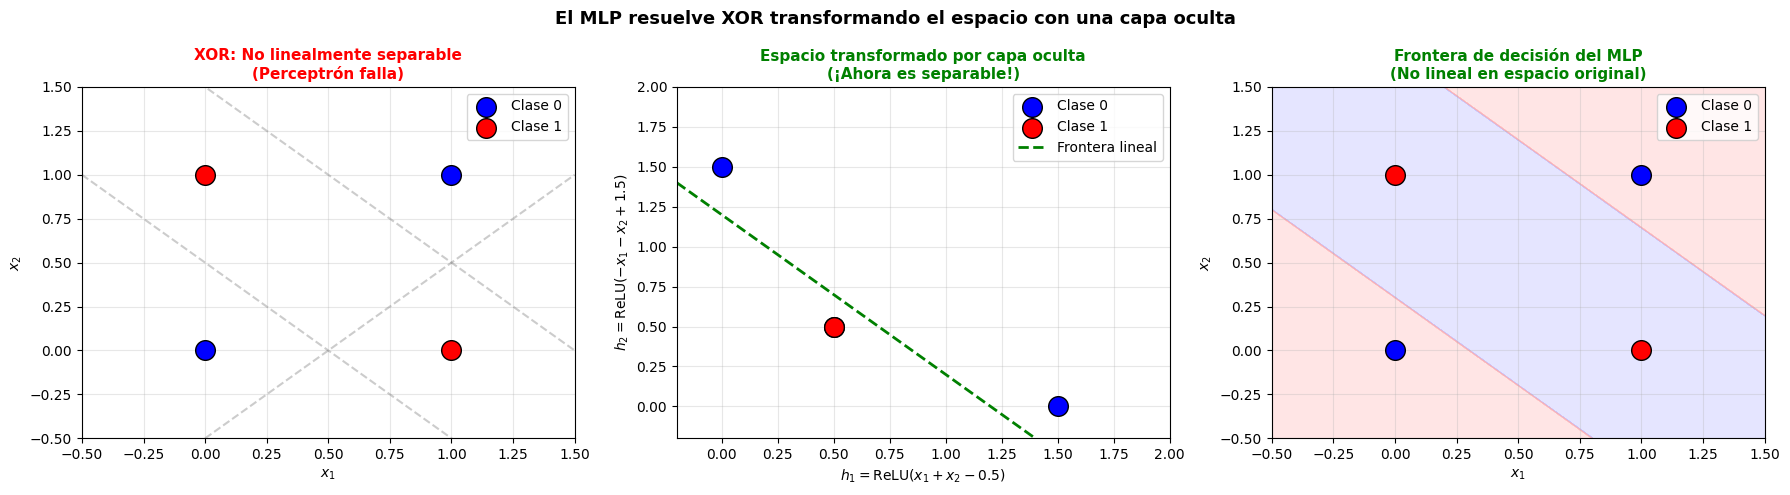

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Visualizar XOR y por qué necesitamos un MLP
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])

# 1. XOR original (no separable)
ax = axes[0]
ax.scatter(X_xor[y_xor==0][:,0], X_xor[y_xor==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='Clase 0')
ax.scatter(X_xor[y_xor==1][:,0], X_xor[y_xor==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='Clase 1')
x_line = np.linspace(-0.5, 1.5, 100)
for s, i in [(-1, 0.5), (-1, 1.5), (1, -0.5)]:
    ax.plot(x_line, s*x_line + i, 'gray', ls='--', alpha=0.4)
ax.set_title('XOR: No linealmente separable\n(Perceptrón falla)', fontsize=11, fontweight='bold', color='red')
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

# 2. Transformación por capa oculta (conceptual)
ax = axes[1]
# Simular transformación: h1 = ReLU(x1 + x2 - 0.5), h2 = ReLU(-x1 - x2 + 1.5)
h1 = np.maximum(0, X_xor[:,0] + X_xor[:,1] - 0.5)
h2 = np.maximum(0, -X_xor[:,0] - X_xor[:,1] + 1.5)
ax.scatter(h1[y_xor==0], h2[y_xor==0], c='blue', s=200, edgecolors='k', zorder=5, label='Clase 0')
ax.scatter(h1[y_xor==1], h2[y_xor==1], c='red', s=200, edgecolors='k', zorder=5, label='Clase 1')
# Ahora SÍ es linealmente separable
h_line = np.linspace(-0.2, 2, 100)
ax.plot(h_line, -h_line + 1.2, 'g--', lw=2, label='Frontera lineal')
ax.set_title('Espacio transformado por capa oculta\n(¡Ahora es separable!)', fontsize=11, fontweight='bold', color='green')
ax.set_xlim(-0.2, 2); ax.set_ylim(-0.2, 2)
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xlabel('$h_1 = \mathrm{ReLU}(x_1+x_2-0.5)$')
ax.set_ylabel('$h_2 = \mathrm{ReLU}(-x_1-x_2+1.5)$')

# 3. Frontera no lineal resultante en el espacio original
ax = axes[2]
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
# Simular MLP: h1, h2 → salida
grid_h1 = np.maximum(0, xx + yy - 0.5)
grid_h2 = np.maximum(0, -xx - yy + 1.5)
grid_out = (grid_h1 + grid_h2 - 1.2)  # combinación lineal
Z = (grid_out > 0).astype(int)

from matplotlib.colors import ListedColormap
cmap_light = ListedColormap(['#AAAAFF', '#FFAAAA'])
ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
ax.scatter(X_xor[y_xor==0][:,0], X_xor[y_xor==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='Clase 0')
ax.scatter(X_xor[y_xor==1][:,0], X_xor[y_xor==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='Clase 1')
ax.set_title('Frontera de decisión del MLP\n(No lineal en espacio original)', fontsize=11, fontweight='bold', color='green')
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

plt.suptitle('El MLP resuelve XOR transformando el espacio con una capa oculta', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## ¿Cómo aprende un MLP?

El MLP aprende mediante un proceso iterativo de tres pasos:

1. **Forward pass**: propagar los datos hacia adelante para obtener una predicción
2. **Calcular la pérdida**: medir qué tan lejos está la predicción del valor real
3. **Backward pass (backpropagation)**: propagar el error hacia atrás para actualizar cada peso

Pero... **¿cómo se calculan exactamente los gradientes capa por capa?** Para eso necesitamos la demostración matemática completa.

## Demostración Matemática

### Paso 1: Forward Pass

Consideremos un MLP con una arquitectura concreta: **entrada → capa oculta → salida**, es decir $L = 2$ capas de pesos.

**Capa 1 (entrada → oculta):**

$$
\mathbf{z}^{[1]} = \mathbf{W}^{[1]} \mathbf{x} + \mathbf{b}^{[1]}
$$

$$
\mathbf{a}^{[1]} = \text{ReLU}(\mathbf{z}^{[1]}) = \max(0, \mathbf{z}^{[1]})
$$

Donde $\mathbf{W}^{[1]} \in \mathbb{R}^{d_h \times d_x}$ y $d_h$ es el número de neuronas ocultas.

**Capa 2 (oculta → salida):**

$$
\mathbf{z}^{[2]} = \mathbf{W}^{[2]} \mathbf{a}^{[1]} + \mathbf{b}^{[2]}
$$

$$
\hat{\mathbf{y}} = \text{softmax}(\mathbf{z}^{[2]}) = \frac{e^{z^{[2]}_c}}{\sum_{j} e^{z^{[2]}_j}}
$$

Donde $\mathbf{W}^{[2]} \in \mathbb{R}^{C \times d_h}$ y $C$ es el número de clases.

**Generalización a $L$ capas:** Simplemente se repite el patrón $\mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}$, $\mathbf{a}^{[l]} = f(\mathbf{z}^{[l]})$ para $l = 1, \dots, L$.

### Paso 2: Función de Pérdida

Para clasificación multiclase, usamos la **entropía cruzada** (cross-entropy):

$$
\mathscr{L} = -\sum_{c=1}^{C} y_c \log(\hat{y}_c)
$$

Donde $\mathbf{y}$ es el vector one-hot de la clase verdadera. Si la clase correcta es $k$:

$$
\mathscr{L} = -\log(\hat{y}_k)
$$

Para un batch de $n$ muestras:

$$
\mathscr{L}_{\text{total}} = \frac{1}{n} \sum_{i=1}^{n} \mathscr{L}_i
$$

**Intuición:** Queremos maximizar la probabilidad $\hat{y}_k$ del label correcto. Como $\log$ es monótona creciente, minimizar $-\log(\hat{y}_k)$ es equivalente a maximizar $\hat{y}_k$.

### Paso 3: Backpropagation (la derivación completa)

El corazón del entrenamiento de redes neuronales. Necesitamos calcular $\frac{\partial \mathscr{L}}{\partial \mathbf{W}^{[l]}}$ y $\frac{\partial \mathscr{L}}{\partial \mathbf{b}^{[l]}}$ para cada capa $l$.

#### Derivada en la capa de salida (Softmax + Cross-Entropy):

Este resultado es elegante: la derivada de la cross-entropy respecto a la pre-activación de softmax es simplemente:

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{z}^{[L]}} = \hat{\mathbf{y}} - \mathbf{y}
$$

**Demostración:**

Sea $\hat{y}_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$ y $\mathscr{L} = -\sum_k y_k \log \hat{y}_k$.

La derivada de softmax es:

$$
\frac{\partial \hat{y}_i}{\partial z_j} = \begin{cases} \hat{y}_i(1 - \hat{y}_j) & \text{si } i = j \\ -\hat{y}_i \hat{y}_j & \text{si } i \neq j \end{cases} = \hat{y}_i(\delta_{ij} - \hat{y}_j)
$$

Entonces:

$$
\frac{\partial \mathscr{L}}{\partial z_j} = -\sum_k y_k \frac{1}{\hat{y}_k} \cdot \hat{y}_k(\delta_{kj} - \hat{y}_j) = -\sum_k y_k(\delta_{kj} - \hat{y}_j) = -y_j + \hat{y}_j \underbrace{\sum_k y_k}_{=1} = \hat{y}_j - y_j \quad \blacksquare
$$

Definimos: $\boldsymbol{\delta}^{[L]} = \hat{\mathbf{y}} - \mathbf{y}$

#### Gradientes de los pesos de la última capa:

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{W}^{[L]}} = \boldsymbol{\delta}^{[L]} (\mathbf{a}^{[L-1]})^T
$$

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{b}^{[L]}} = \boldsymbol{\delta}^{[L]}
$$

#### Propagación hacia atrás (capa $l < L$):

El error se propaga hacia la capa anterior:

$$
\boldsymbol{\delta}^{[l]} = \left((\mathbf{W}^{[l+1]})^T \boldsymbol{\delta}^{[l+1]}\right) \odot f'^{[l]}(\mathbf{z}^{[l]})
$$

Donde $\odot$ es el producto elemento a elemento y $f'$ es la derivada de la activación.

Para **ReLU**: $f'(z) = \begin{cases} 1 & \text{si } z > 0 \\ 0 & \text{si } z \leq 0 \end{cases}$

Los gradientes de los pesos:

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{W}^{[l]}} = \boldsymbol{\delta}^{[l]} (\mathbf{a}^{[l-1]})^T
$$

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{b}^{[l]}} = \boldsymbol{\delta}^{[l]}
$$

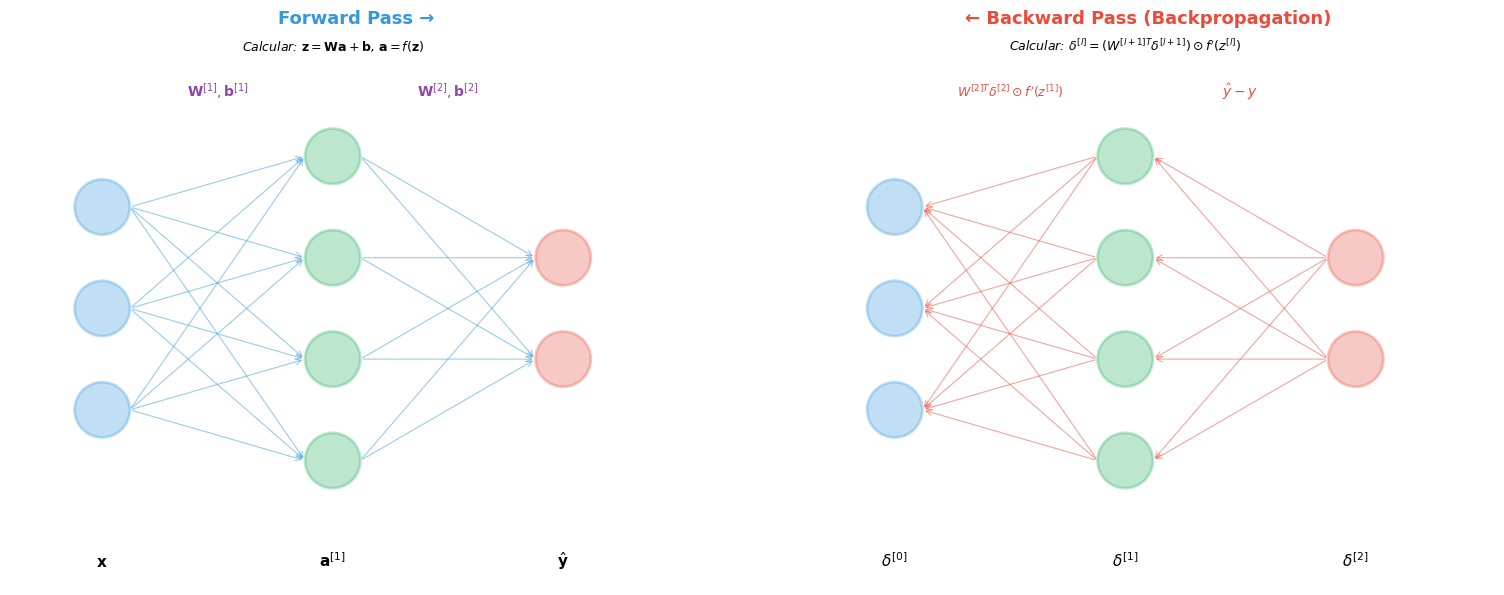

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Visualizar Forward y Backward en un MLP
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Forward Pass ---
ax = axes[0]
ax.set_xlim(-0.5, 7)
ax.set_ylim(-0.5, 5.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Forward Pass →', fontsize=13, fontweight='bold', color='#3498db')

layers_fw = [(0.5, 3, '#3498db', '$\mathbf{x}$'), (3, 4, '#27ae60', '$\mathbf{a}^{[1]}$'), (5.5, 2, '#e74c3c', '$\hat{\mathbf{y}}$')]
positions_fw = []
for x, n, color, label in layers_fw:
    pos = []
    total_h = (n - 1) * 1.1
    start = 2.5 - total_h / 2
    for i in range(n):
        y = start + i * 1.1
        c = plt.Circle((x, y), 0.3, color=color, alpha=0.3, ec=color, lw=2)
        ax.add_patch(c)
        pos.append((x, y))
    positions_fw.append(pos)
    ax.text(x, -0.3, label, ha='center', fontsize=11, fontweight='bold')

for l in range(len(positions_fw)-1):
    for x1, y1 in positions_fw[l]:
        for x2, y2 in positions_fw[l+1]:
            ax.annotate('', xy=(x2-0.3, y2), xytext=(x1+0.3, y1),
                       arrowprops=dict(arrowstyle='->', color='#3498db', lw=0.8, alpha=0.5))

ax.text(1.75, 4.8, '$\mathbf{W}^{[1]}, \mathbf{b}^{[1]}$', ha='center', fontsize=10, color='#8e44ad')
ax.text(4.25, 4.8, '$\mathbf{W}^{[2]}, \mathbf{b}^{[2]}$', ha='center', fontsize=10, color='#8e44ad')
ax.text(3, 5.3, 'Calcular: $\mathbf{z} = \mathbf{W}\mathbf{a} + \mathbf{b}$, $\mathbf{a} = f(\mathbf{z})$',
        ha='center', fontsize=9, fontstyle='italic')

# --- Backward Pass ---
ax = axes[1]
ax.set_xlim(-0.5, 7)
ax.set_ylim(-0.5, 5.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('← Backward Pass (Backpropagation)', fontsize=13, fontweight='bold', color='#e74c3c')

layers_bw = [(0.5, 3, '#3498db', '$\delta^{[0]}$'), (3, 4, '#27ae60', '$\delta^{[1]}$'), (5.5, 2, '#e74c3c', '$\delta^{[2]}$')]
positions_bw = []
for x, n, color, label in layers_bw:
    pos = []
    total_h = (n - 1) * 1.1
    start = 2.5 - total_h / 2
    for i in range(n):
        y = start + i * 1.1
        c = plt.Circle((x, y), 0.3, color=color, alpha=0.3, ec=color, lw=2)
        ax.add_patch(c)
        pos.append((x, y))
    positions_bw.append(pos)
    ax.text(x, -0.3, label, ha='center', fontsize=11, fontweight='bold')

for l in range(len(positions_bw)-1, 0, -1):
    for x1, y1 in positions_bw[l]:
        for x2, y2 in positions_bw[l-1]:
            ax.annotate('', xy=(x2+0.3, y2), xytext=(x1-0.3, y1),
                       arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=0.8, alpha=0.5))

ax.text(4.25, 4.8, '$\hat{y} - y$', ha='center', fontsize=10, color='#e74c3c')
ax.text(1.75, 4.8, '$W^{[2]T}\delta^{[2]} \odot f\'(z^{[1]})$', ha='center', fontsize=9, color='#e74c3c')
ax.text(3, 5.3, 'Calcular: $\delta^{[l]} = (W^{[l+1]T}\delta^{[l+1]}) \odot f\'(z^{[l]})$',
        ha='center', fontsize=9, fontstyle='italic')

plt.tight_layout()
plt.show()

### Paso 4: Descenso de Gradiente

Con los gradientes calculados, actualizamos los pesos usando **Stochastic Gradient Descent (SGD)**:

$$
\mathbf{W}^{[l]} \leftarrow \mathbf{W}^{[l]} - \eta \frac{\partial \mathscr{L}}{\partial \mathbf{W}^{[l]}}
$$

$$
\mathbf{b}^{[l]} \leftarrow \mathbf{b}^{[l]} - \eta \frac{\partial \mathscr{L}}{\partial \mathbf{b}^{[l]}}
$$

**Variantes de SGD:**

| Optimizador | Actualización | Ventaja |
|---|---|---|
| **SGD** | $\Delta w = -\eta \nabla \mathscr{L}$ | Simple, funciona bien con LR scheduling |
| **SGD + Momentum** | $v = \beta v - \eta \nabla \mathscr{L}$, $\Delta w = v$ | Acelera convergencia, suaviza oscilaciones |
| **Adam** | Combina momentum + tasa adaptativa por parámetro | Converge rápido, bueno por defecto |

Usaremos SGD simple en nuestra implementación.

### Paso 5: Inicialización de Pesos

La inicialización de pesos es **crucial** para el entrenamiento exitoso. Si los pesos son:
- **Muy grandes**: activaciones saturan, gradientes explotan
- **Muy pequeños**: señal desaparece, gradientes se desvanecen
- **Todos iguales**: todas las neuronas calculan lo mismo ("simetría rota")

**Xavier Initialization** (Glorot, 2010): Para activaciones tanh/sigmoide:

$$
W^{[l]} \sim \mathscr{N}\left(0, \frac{2}{n^{[l-1]} + n^{[l]}}\right)
$$

**He Initialization** (He, 2015): Para activaciones ReLU:

$$
W^{[l]} \sim \mathscr{N}\left(0, \frac{2}{n^{[l-1]}}\right)
$$

La idea es mantener la **varianza de las activaciones** constante a lo largo de las capas.

### Ejemplo numérico

Veamos un forward + backward pass completo con un MLP de arquitectura $2 \to 2 \to 2$.

**Datos:** $\mathbf{x} = (1, 0)^T$, clase verdadera: $y = 1$ → $\mathbf{y} = (0, 1)^T$

**Pesos (simplificados):**

$$
\mathbf{W}^{[1]} = \begin{bmatrix} 0.5 & 0.3 \\ -0.2 & 0.8 \end{bmatrix}, \quad
\mathbf{b}^{[1]} = \begin{bmatrix} 0.1 \\ -0.1 \end{bmatrix}
$$

$$
\mathbf{W}^{[2]} = \begin{bmatrix} 0.4 & -0.3 \\ 0.1 & 0.6 \end{bmatrix}, \quad
\mathbf{b}^{[2]} = \begin{bmatrix} 0.0 \\ 0.0 \end{bmatrix}
$$

**Forward Pass:**

$$
\mathbf{z}^{[1]} = \begin{bmatrix} 0.5 & 0.3 \\ -0.2 & 0.8 \end{bmatrix} \begin{bmatrix} 1 \\ 0 \end{bmatrix} + \begin{bmatrix} 0.1 \\ -0.1 \end{bmatrix} = \begin{bmatrix} 0.6 \\ -0.3 \end{bmatrix}
$$

$$
\mathbf{a}^{[1]} = \text{ReLU}(\mathbf{z}^{[1]}) = \begin{bmatrix} 0.6 \\ 0.0 \end{bmatrix}
$$

$$
\mathbf{z}^{[2]} = \begin{bmatrix} 0.4 & -0.3 \\ 0.1 & 0.6 \end{bmatrix} \begin{bmatrix} 0.6 \\ 0.0 \end{bmatrix} + \begin{bmatrix} 0 \\ 0 \end{bmatrix} = \begin{bmatrix} 0.24 \\ 0.06 \end{bmatrix}
$$

$$
\hat{\mathbf{y}} = \text{softmax}(\mathbf{z}^{[2]}) = \frac{1}{e^{0.24}+e^{0.06}} \begin{bmatrix} e^{0.24} \\ e^{0.06} \end{bmatrix} = \begin{bmatrix} 0.545 \\ 0.455 \end{bmatrix}
$$

$$
\mathscr{L} = -\log(0.455) = 0.787
$$

In [ ]:
import numpy as np

# Ejemplo numérico completo: Forward + Backward
np.set_printoptions(precision=4, suppress=True)

# Datos
x = np.array([1.0, 0.0])
y_true = 1  # clase 1
y_onehot = np.array([0.0, 1.0])

# Pesos
W1 = np.array([[0.5, 0.3], [-0.2, 0.8]])
b1 = np.array([0.1, -0.1])
W2 = np.array([[0.4, -0.3], [0.1, 0.6]])
b2 = np.array([0.0, 0.0])

lr = 0.1

def softmax(z):
    e_z = np.exp(z - np.max(z))
    return e_z / e_z.sum()

print("=" * 60)
print("FORWARD PASS")
print("=" * 60)

# Capa 1
z1 = W1 @ x + b1
a1 = np.maximum(0, z1)  # ReLU
print(f"z¹ = W¹·x + b¹ = {z1}")
print(f"a¹ = ReLU(z¹) = {a1}")

# Capa 2
z2 = W2 @ a1 + b2
y_hat = softmax(z2)
print(f"\nz² = W²·a¹ + b² = {z2}")
print(f"ŷ = softmax(z²) = {y_hat}")

# Pérdida
loss = -np.log(y_hat[y_true] + 1e-10)
print(f"\nLoss = -log(ŷ[{y_true}]) = -log({y_hat[y_true]:.4f}) = {loss:.4f}")

print(f"\nPredicción: clase {np.argmax(y_hat)} (prob={y_hat[np.argmax(y_hat)]:.4f})")
print(f"Real: clase {y_true}")

print("\n" + "=" * 60)
print("BACKWARD PASS")
print("=" * 60)

# δ² = ŷ - y
delta2 = y_hat - y_onehot
print(f"δ² = ŷ - y = {y_hat} - {y_onehot} = {delta2}")

# Gradientes de W² y b²
dW2 = np.outer(delta2, a1)
db2 = delta2
print(f"\ndW² = δ² · (a¹)ᵀ = \n{dW2}")
print(f"db² = δ² = {db2}")

# Propagar hacia capa 1
# δ¹ = (W²ᵀ δ²) ⊙ ReLU'(z¹)
relu_grad = (z1 > 0).astype(float)
delta1 = (W2.T @ delta2) * relu_grad
print(f"\nReLU'(z¹) = {relu_grad}")
print(f"δ¹ = (W²ᵀ · δ²) ⊙ ReLU'(z¹) = {delta1}")

# Gradientes de W¹ y b¹
dW1 = np.outer(delta1, x)
db1 = delta1
print(f"\ndW¹ = δ¹ · xᵀ = \n{dW1}")
print(f"db¹ = δ¹ = {db1}")

print("\n" + "=" * 60)
print("ACTUALIZACIÓN DE PESOS (η = 0.1)")
print("=" * 60)

W2_new = W2 - lr * dW2
b2_new = b2 - lr * db2
W1_new = W1 - lr * dW1
b1_new = b1 - lr * db1

print(f"W² nuevo = \n{W2_new}")
print(f"W¹ nuevo = \n{W1_new}")

# Verificar que el loss baja
z1_v = W1_new @ x + b1_new
a1_v = np.maximum(0, z1_v)
z2_v = W2_new @ a1_v + b2_new
y_hat_v = softmax(z2_v)
loss_v = -np.log(y_hat_v[y_true] + 1e-10)

print(f"\nVerificación:")
print(f"  Loss antes: {loss:.4f}")
print(f"  Loss después: {loss_v:.4f}")
print(f"  ΔLoss: {loss_v - loss:.4f} {'✓ bajó' if loss_v < loss else '✗ subió'}")

FORWARD PASS
z¹ = W¹·x + b¹ = [ 0.6 -0.3]
a¹ = ReLU(z¹) = [0.6 0. ]

z² = W²·a¹ + b² = [0.24 0.06]
ŷ = softmax(z²) = [0.5449 0.4551]

Loss = -log(ŷ[1]) = -log(0.4551) = 0.7872

Predicción: clase 0 (prob=0.5449)
Real: clase 1

BACKWARD PASS
δ² = ŷ - y = [0.5449 0.4551] - [0. 1.] = [ 0.5449 -0.5449]

dW² = δ² · (a¹)ᵀ = 
[[ 0.3269  0.    ]
 [-0.3269 -0.    ]]
db² = δ² = [ 0.5449 -0.5449]

ReLU'(z¹) = [1. 0.]
δ¹ = (W²ᵀ · δ²) ⊙ ReLU'(z¹) = [ 0.1635 -0.    ]

dW¹ = δ¹ · xᵀ = 
[[ 0.1635  0.    ]
 [-0.     -0.    ]]
db¹ = δ¹ = [ 0.1635 -0.    ]

ACTUALIZACIÓN DE PESOS (η = 0.1)
W² nuevo = 
[[ 0.3673 -0.3   ]
 [ 0.1327  0.6   ]]
W¹ nuevo = 
[[ 0.4837  0.3   ]
 [-0.2     0.8   ]]

Verificación:
  Loss antes: 0.7872
  Loss después: 0.7053
  ΔLoss: -0.0819 ✓ bajó


### Algoritmo Completo del MLP

---

**Entrada:** Datos $(\mathbf{X}, \mathbf{y})$, arquitectura $[n_0, n_1, \dots, n_L]$, tasa $\eta$, épocas $E$

**Inicialización:** Para $l = 1, \dots, L$:

$\quad$ $\mathbf{W}^{[l]} \sim \mathscr{N}(0, \sqrt{2/n_{l-1}})$ (He initialization)

$\quad$ $\mathbf{b}^{[l]} = \mathbf{0}$

**Para** cada época $e = 1, \dots, E$:

$\quad$ **Para** cada muestra $(\mathbf{x}_i, y_i)$:

$\quad\quad$ **Forward:** $\mathbf{a}^{[0]} = \mathbf{x}_i$

$\quad\quad\quad$ Para $l = 1, \dots, L$: $\mathbf{z}^{[l]} = \mathbf{W}^{[l]}\mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}$, $\mathbf{a}^{[l]} = f^{[l]}(\mathbf{z}^{[l]})$

$\quad\quad$ **Loss:** $\mathscr{L} = -\log(\hat{y}_{y_i})$

$\quad\quad$ **Backward:** $\boldsymbol{\delta}^{[L]} = \hat{\mathbf{y}} - \mathbf{y}_i$

$\quad\quad\quad$ Para $l = L, L-1, \dots, 1$:

$\quad\quad\quad\quad$ $d\mathbf{W}^{[l]} = \boldsymbol{\delta}^{[l]} (\mathbf{a}^{[l-1]})^T$

$\quad\quad\quad\quad$ $d\mathbf{b}^{[l]} = \boldsymbol{\delta}^{[l]}$

$\quad\quad\quad\quad$ Si $l > 1$: $\boldsymbol{\delta}^{[l-1]} = (\mathbf{W}^{[l]T} \boldsymbol{\delta}^{[l]}) \odot f'^{[l-1]}(\mathbf{z}^{[l-1]})$

$\quad\quad$ **Actualizar:** $\mathbf{W}^{[l]} \leftarrow \mathbf{W}^{[l]} - \eta \cdot d\mathbf{W}^{[l]}$, $\mathbf{b}^{[l]} \leftarrow \mathbf{b}^{[l]} - \eta \cdot d\mathbf{b}^{[l]}$

---

## Implementación con Código

### Funciones

In [ ]:
import numpy as np

# Activaciones
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def softmax(z):
    e_z = np.exp(z - np.max(z))
    return e_z / e_z.sum()

# Inicialización
def init_weights(layer_sizes):
    """He initialization para cada capa"""
    weights = []
    biases = []
    for i in range(1, len(layer_sizes)):
        W = np.random.randn(layer_sizes[i], layer_sizes[i-1]) * np.sqrt(2.0 / layer_sizes[i-1])
        b = np.zeros(layer_sizes[i])
        weights.append(W)
        biases.append(b)
    return weights, biases

# Forward Pass
def mlp_forward(x, weights, biases):
    """Forward pass guardando cache para backprop"""
    L = len(weights)
    a = x.copy()
    cache = {'a': [a], 'z': []}

    for l in range(L):
        z = weights[l] @ a + biases[l]
        cache['z'].append(z)

        if l < L - 1:  # Capas ocultas: ReLU
            a = relu(z)
        else:           # Última capa: Softmax
            a = softmax(z)

        cache['a'].append(a)

    return a, cache

# Backward Pass
def mlp_backward(y_true, cache, weights):
    """Backward pass (backpropagation)"""
    L = len(weights)
    dW = [None] * L
    db = [None] * L

    # δ de la última capa (softmax + CE)
    y_onehot = np.zeros_like(cache['a'][-1])
    y_onehot[y_true] = 1
    delta = cache['a'][-1] - y_onehot  # ŷ - y

    for l in range(L - 1, -1, -1):
        dW[l] = np.outer(delta, cache['a'][l])
        db[l] = delta

        if l > 0:
            delta = (weights[l].T @ delta) * relu_derivative(cache['z'][l-1])

    return dW, db

# Entrenamiento
def mlp_train(X, y, layer_sizes, lr=0.01, epochs=100):
    """Entrena un MLP con SGD"""
    weights, biases = init_weights(layer_sizes)
    losses = []

    for epoch in range(epochs):
        epoch_loss = 0
        correct = 0
        indices = np.random.permutation(len(X))

        for idx in indices:
            # Forward
            probs, cache = mlp_forward(X[idx], weights, biases)
            epoch_loss += -np.log(probs[y[idx]] + 1e-10)
            if np.argmax(probs) == y[idx]:
                correct += 1

            # Backward
            dW, db = mlp_backward(y[idx], cache, weights)

            # Update
            for l in range(len(weights)):
                weights[l] -= lr * dW[l]
                biases[l] -= lr * db[l]

        losses.append(epoch_loss / len(X))

    return weights, biases, losses

def mlp_predict(X, weights, biases):
    """Predice clases para un batch"""
    preds = []
    for x in X:
        probs, _ = mlp_forward(x, weights, biases)
        preds.append(np.argmax(probs))
    return np.array(preds)


print("Funciones de MLP definidas correctamente.")

Funciones de MLP definidas correctamente.


In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
import numpy as np

# Entrenar con funciones en Iris
iris = datasets.load_iris()
X, y = iris.data, iris.target

# Normalizar
X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Arquitectura: 4 → 16 → 8 → 3
np.random.seed(42)
layer_sizes = [4, 16, 8, 3]
weights, biases, losses = mlp_train(X_train, y_train, layer_sizes, lr=0.01, epochs=100)

# Evaluar
preds = mlp_predict(X_test, weights, biases)
accuracy = np.sum(preds == y_test) / len(y_test)
print(f"Arquitectura: {layer_sizes}")
print(f"Accuracy en test: {accuracy:.4f}")
print(f"Loss final: {losses[-1]:.4f}")

Arquitectura: [4, 16, 8, 3]
Accuracy en test: 1.0000
Loss final: 0.0536


### Clase

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class MLP:
    """
    Perceptrón Multicapa desde cero.
    Soporta arquitectura arbitraria (cualquier número de capas y neuronas).
    Activación: ReLU para ocultas, Softmax para salida.
    Pérdida: Cross-Entropy.
    Optimizador: SGD.
    """
    def __init__(self, layer_sizes, learning_rate=0.01):
        """
        layer_sizes: lista con el número de neuronas por capa.
                     Ej: [4, 16, 8, 3] → 4 entradas, 2 capas ocultas (16 y 8), 3 salidas
        """
        self.layer_sizes = layer_sizes
        self.lr = learning_rate
        self.L = len(layer_sizes) - 1  # número de capas de pesos
        self.loss_history = []
        self.acc_history = []

        # He initialization
        self.weights = []
        self.biases = []
        for l in range(self.L):
            W = np.random.randn(layer_sizes[l+1], layer_sizes[l]) * np.sqrt(2.0 / layer_sizes[l])
            b = np.zeros(layer_sizes[l+1])
            self.weights.append(W)
            self.biases.append(b)

    def _relu(self, z):
        return np.maximum(0, z)

    def _relu_deriv(self, z):
        return (z > 0).astype(float)

    def _softmax(self, z):
        e_z = np.exp(z - np.max(z))
        return e_z / e_z.sum()

    def _forward(self, x):
        """Forward pass para una muestra"""
        a = x.copy()
        cache = {'a': [a], 'z': []}

        for l in range(self.L):
            z = self.weights[l] @ a + self.biases[l]
            cache['z'].append(z)

            if l < self.L - 1:
                a = self._relu(z)
            else:
                a = self._softmax(z)

            cache['a'].append(a)

        return a, cache

    def _backward(self, y_true, cache):
        """Backward pass (backpropagation)"""
        dW = [None] * self.L
        db = [None] * self.L

        # Delta de la capa de salida
        y_onehot = np.zeros(self.layer_sizes[-1])
        y_onehot[y_true] = 1
        delta = cache['a'][-1] - y_onehot

        for l in range(self.L - 1, -1, -1):
            dW[l] = np.outer(delta, cache['a'][l])
            db[l] = delta

            if l > 0:
                delta = (self.weights[l].T @ delta) * self._relu_deriv(cache['z'][l-1])

        return dW, db

    def fit(self, X, y, epochs=100, verbose=True):
        """Entrena el MLP"""
        n_samples = len(X)
        self.loss_history = []
        self.acc_history = []

        for epoch in range(epochs):
            epoch_loss = 0
            correct = 0
            indices = np.random.permutation(n_samples)

            for idx in indices:
                # Forward
                probs, cache = self._forward(X[idx])
                epoch_loss += -np.log(probs[y[idx]] + 1e-10)
                if np.argmax(probs) == y[idx]:
                    correct += 1

                # Backward
                dW, db = self._backward(y[idx], cache)

                # Update (SGD)
                for l in range(self.L):
                    self.weights[l] -= self.lr * dW[l]
                    self.biases[l] -= self.lr * db[l]

            avg_loss = epoch_loss / n_samples
            accuracy = correct / n_samples
            self.loss_history.append(avg_loss)
            self.acc_history.append(accuracy)

            if verbose and (epoch + 1) % max(1, epochs // 10) == 0:
                print(f"Época {epoch+1:4d}/{epochs} — Loss: {avg_loss:.4f} — Accuracy: {accuracy:.4f}")

    def predict(self, X):
        """Predice clases"""
        preds = []
        for x in X:
            probs, _ = self._forward(x)
            preds.append(np.argmax(probs))
        return np.array(preds)

    def predict_proba(self, X):
        """Retorna probabilidades"""
        all_probs = []
        for x in X:
            probs, _ = self._forward(x)
            all_probs.append(probs)
        return np.array(all_probs)

    def score(self, X, y):
        """Calcula accuracy"""
        preds = self.predict(X)
        return np.sum(preds == y) / len(y)

    def plot_loss(self):
        """Grafica loss y accuracy durante entrenamiento"""
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        axes[0].plot(range(1, len(self.loss_history)+1), self.loss_history,
                     color='#e74c3c', linewidth=1.5)
        axes[0].set_xlabel('Época', fontsize=11)
        axes[0].set_ylabel('Loss (Cross-Entropy)', fontsize=11)
        axes[0].set_title('Curva de Pérdida', fontsize=12, fontweight='bold')
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(range(1, len(self.acc_history)+1), self.acc_history,
                     color='#27ae60', linewidth=1.5)
        axes[1].set_xlabel('Época', fontsize=11)
        axes[1].set_ylabel('Accuracy', fontsize=11)
        axes[1].set_title('Curva de Accuracy', fontsize=12, fontweight='bold')
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1.05)

        arch_str = ' → '.join(str(s) for s in self.layer_sizes)
        plt.suptitle(f'Entrenamiento del MLP [{arch_str}]', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

    def plot_decision_boundary(self, X, y, feature_indices=(0, 1), title=None):
        """Grafica frontera de decisión (2D)"""
        i, j = feature_indices
        X_2d = X[:, [i, j]]

        # Crear MLP temporal con 2 features
        temp = MLP([2] + self.layer_sizes[1:], learning_rate=self.lr)
        # Entrenar rápido
        temp.fit(X_2d, y, epochs=200, verbose=False)

        h = 0.1
        x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
        y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
        grid = np.c_[xx.ravel(), yy.ravel()]
        Z = temp.predict(grid).reshape(xx.shape)

        n_classes = len(np.unique(y))
        if n_classes <= 3:
            cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'][:n_classes])
            cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'][:n_classes])
        else:
            cmap_light = plt.cm.Pastel1
            cmap_bold = plt.cm.Set1

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=cmap_bold, edgecolors='k', s=40)
        plt.xlabel(f'Feature {i}', fontsize=11)
        plt.ylabel(f'Feature {j}', fontsize=11)
        arch_str = ' → '.join(str(s) for s in self.layer_sizes)
        plt.title(title or f'Frontera de Decisión MLP [{arch_str}]', fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
import numpy as np

# Cargar y normalizar Iris
iris = datasets.load_iris()
X, y = iris.data, iris.target
X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar MLP
np.random.seed(42)
model = MLP(layer_sizes=[4, 16, 8, 3], learning_rate=0.01)
model.fit(X_train, y_train, epochs=200, verbose=True)

Época   20/200 — Loss: 0.0915 — Accuracy: 0.9750
Época   40/200 — Loss: 0.0808 — Accuracy: 0.9583
Época   60/200 — Loss: 0.0563 — Accuracy: 0.9833
Época   80/200 — Loss: 0.0581 — Accuracy: 0.9667
Época  100/200 — Loss: 0.0536 — Accuracy: 0.9833
Época  120/200 — Loss: 0.0420 — Accuracy: 0.9917
Época  140/200 — Loss: 0.0301 — Accuracy: 0.9917
Época  160/200 — Loss: 0.0403 — Accuracy: 0.9833
Época  180/200 — Loss: 0.0287 — Accuracy: 0.9917
Época  200/200 — Loss: 0.0246 — Accuracy: 0.9917


In [ ]:
# Evaluar
train_acc = model.score(X_train, y_train)
test_acc = model.score(X_test, y_test)
print(f"Accuracy en entrenamiento: {train_acc:.4f}")
print(f"Accuracy en prueba: {test_acc:.4f}")

Accuracy en entrenamiento: 0.9917
Accuracy en prueba: 1.0000


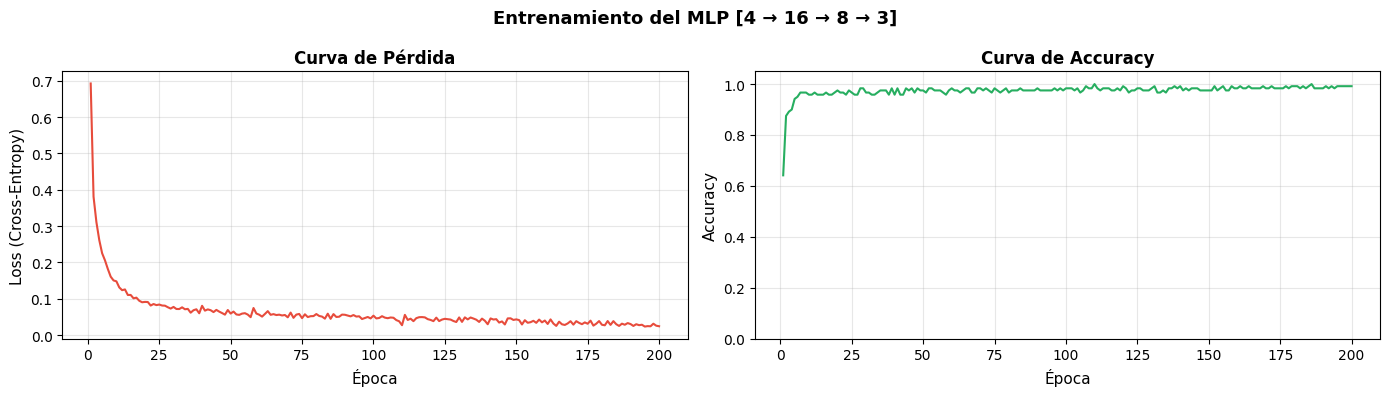

In [ ]:
# Visualizar curvas de entrenamiento
model.plot_loss()

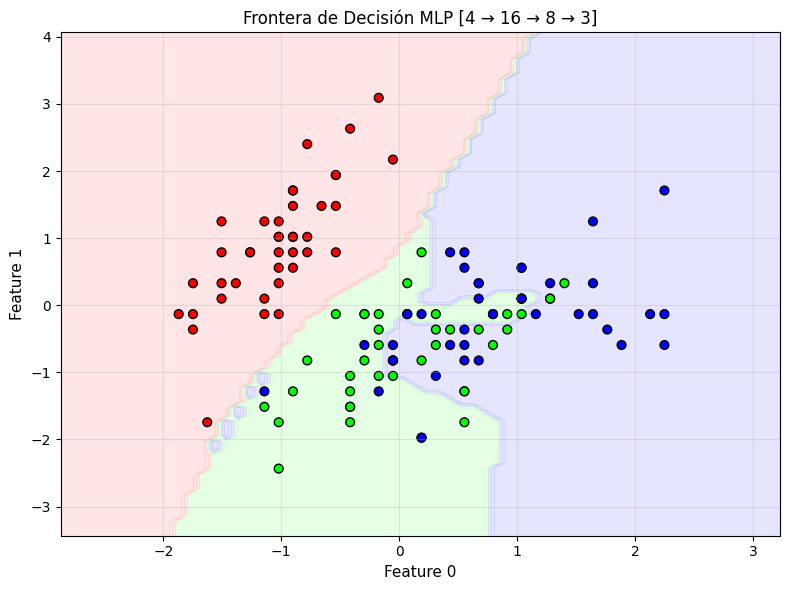

In [ ]:
# Frontera de decisión
model.plot_decision_boundary(X_train, y_train, feature_indices=(0, 1))

In [ ]:
# El MLP resuelve XOR
print("="*60)

X_xor = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

np.random.seed(42)
mlp_xor = MLP(layer_sizes=[2, 8, 2], learning_rate=0.1)
mlp_xor.fit(X_xor, y_xor, epochs=500, verbose=True)

preds = mlp_xor.predict(X_xor)
print(f"\nPredicciones:")
for x_i, y_true, y_pred in zip(X_xor, y_xor, preds):
    status = '✓' if y_true == y_pred else '✗'
    print(f"  x={x_i} → Predicho: {y_pred}, Real: {y_true} {status}")
print(f"\nAccuracy: {mlp_xor.score(X_xor, y_xor):.4f}")

Época   50/500 — Loss: 0.4508 — Accuracy: 0.7500
Época  100/500 — Loss: 0.1459 — Accuracy: 1.0000
Época  150/500 — Loss: 0.0522 — Accuracy: 1.0000
Época  200/500 — Loss: 0.0291 — Accuracy: 1.0000
Época  250/500 — Loss: 0.0196 — Accuracy: 1.0000
Época  300/500 — Loss: 0.0146 — Accuracy: 1.0000
Época  350/500 — Loss: 0.0115 — Accuracy: 1.0000
Época  400/500 — Loss: 0.0095 — Accuracy: 1.0000
Época  450/500 — Loss: 0.0080 — Accuracy: 1.0000
Época  500/500 — Loss: 0.0069 — Accuracy: 1.0000

Predicciones:
  x=[0. 0.] → Predicho: 0, Real: 0 ✓
  x=[0. 1.] → Predicho: 1, Real: 1 ✓
  x=[1. 0.] → Predicho: 1, Real: 1 ✓
  x=[1. 1.] → Predicho: 0, Real: 0 ✓

Accuracy: 1.0000


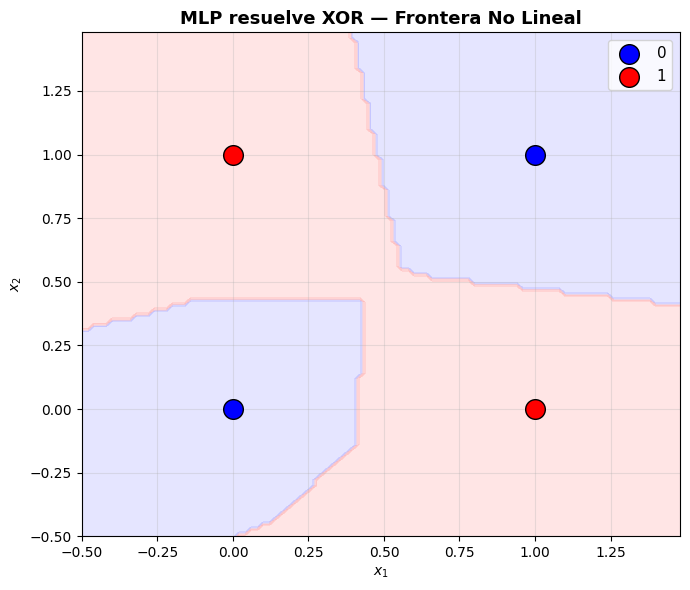

In [ ]:
# Visualizar frontera de decisión en XOR
h = 0.02
xx, yy = np.meshgrid(np.arange(-0.5, 1.5, h), np.arange(-0.5, 1.5, h))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = mlp_xor.predict(grid).reshape(xx.shape)

cmap_light = ListedColormap(['#AAAAFF', '#FFAAAA'])
plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
plt.scatter(X_xor[y_xor==0][:,0], X_xor[y_xor==0][:,1], c='blue', s=200, edgecolors='k', zorder=5, label='0')
plt.scatter(X_xor[y_xor==1][:,0], X_xor[y_xor==1][:,1], c='red', s=200, edgecolors='k', zorder=5, label='1')
plt.title('MLP resuelve XOR — Frontera No Lineal', fontsize=13, fontweight='bold')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

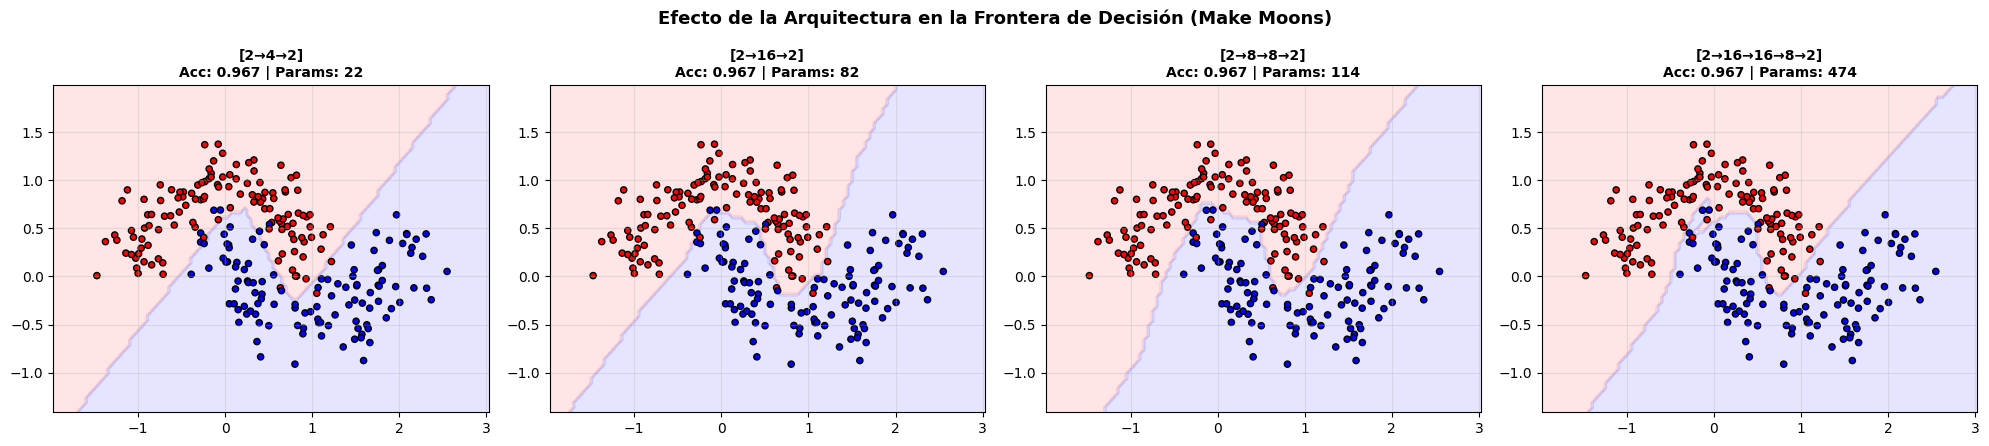

In [ ]:
# Comparar diferentes arquitecturas
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Dataset más complejo: make_moons
X_moons, y_moons = datasets.make_moons(n_samples=300, noise=0.2, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=42)

architectures = [
    [2, 4, 2],        # Muy simple
    [2, 16, 2],       # 1 capa, más neuronas
    [2, 8, 8, 2],     # 2 capas ocultas
    [2, 16, 16, 8, 2] # 3 capas ocultas
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for ax, arch in zip(axes, architectures):
    np.random.seed(42)
    m = MLP(layer_sizes=arch, learning_rate=0.05)
    m.fit(X_train_m, y_train_m, epochs=300, verbose=False)

    test_acc = m.score(X_test_m, y_test_m)
    n_params = sum(m.weights[l].size + m.biases[l].size for l in range(m.L))

    h = 0.05
    x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
    y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = m.predict(grid).reshape(xx.shape)

    cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
    ax.scatter(X_train_m[:, 0], X_train_m[:, 1], c=y_train_m, cmap=ListedColormap(['#FF0000','#0000FF']),
               edgecolors='k', s=20)

    arch_str = '→'.join(str(s) for s in arch)
    ax.set_title(f'[{arch_str}]\nAcc: {test_acc:.3f} | Params: {n_params}',
                 fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Efecto de la Arquitectura en la Frontera de Decisión (Make Moons)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Test en dígitos (clasificación multiclase)
from sklearn import datasets
from sklearn.model_selection import train_test_split

digits = datasets.load_digits()
X_d = digits.data / 16.0  # Normalizar
y_d = digits.target

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42)

print(f"Dígitos: {X_train_d.shape[0]} train, {X_test_d.shape[0]} test")
print(f"Features: {X_train_d.shape[1]} (imagen 8×8 aplanada)")
print(f"Clases: {len(np.unique(y_d))}")

np.random.seed(42)
model_digits = MLP(layer_sizes=[64, 32, 16, 10], learning_rate=0.005)
model_digits.fit(X_train_d, y_train_d, epochs=50, verbose=True)

train_acc = model_digits.score(X_train_d, y_train_d)
test_acc = model_digits.score(X_test_d, y_test_d)
print(f"\nAccuracy train: {train_acc:.4f}")
print(f"Accuracy test: {test_acc:.4f}")

Dígitos: 1437 train, 360 test
Features: 64 (imagen 8×8 aplanada)
Clases: 10
Época    5/50 — Loss: 0.2120 — Accuracy: 0.9388
Época   10/50 — Loss: 0.0996 — Accuracy: 0.9715
Época   15/50 — Loss: 0.0606 — Accuracy: 0.9833
Época   20/50 — Loss: 0.0422 — Accuracy: 0.9910
Época   25/50 — Loss: 0.0299 — Accuracy: 0.9944
Época   30/50 — Loss: 0.0208 — Accuracy: 0.9951
Época   35/50 — Loss: 0.0151 — Accuracy: 0.9979
Época   40/50 — Loss: 0.0132 — Accuracy: 0.9958
Época   45/50 — Loss: 0.0096 — Accuracy: 0.9986
Época   50/50 — Loss: 0.0075 — Accuracy: 0.9986

Accuracy train: 1.0000
Accuracy test: 0.9667


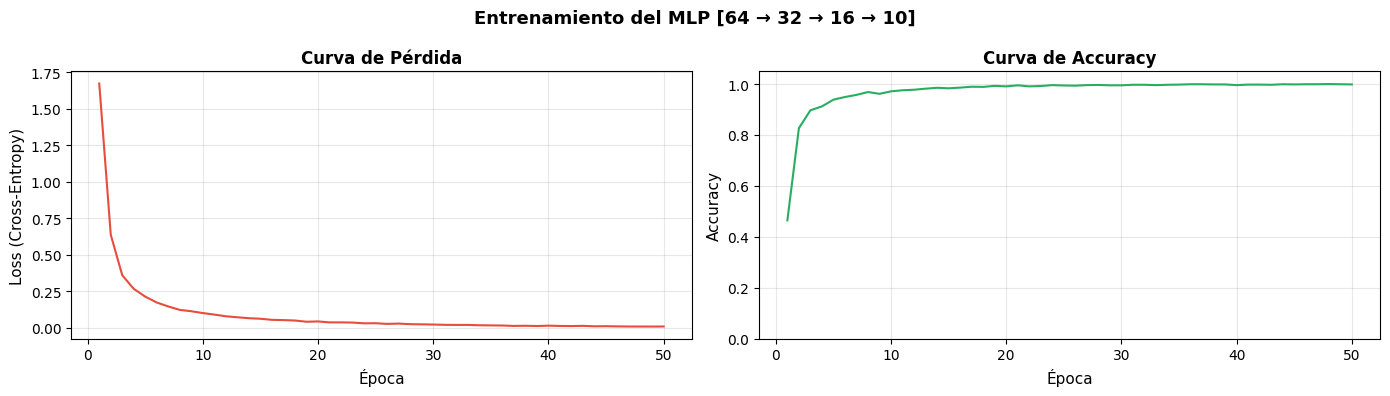

In [ ]:
# Curvas de entrenamiento
model_digits.plot_loss()

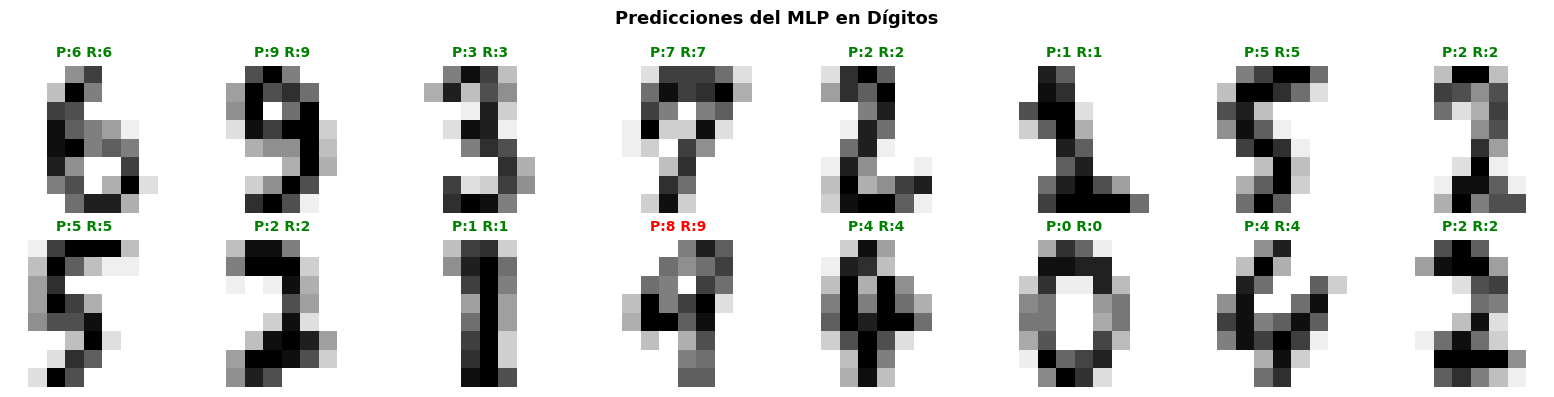

In [ ]:
# Visualizar predicciones en dígitos
preds_d = model_digits.predict(X_test_d)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test_d[i].reshape(8, 8), cmap='gray_r')
    color = 'green' if preds_d[i] == y_test_d[i] else 'red'
    ax.set_title(f'P:{preds_d[i]} R:{y_test_d[i]}', fontsize=10, color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Predicciones del MLP en Dígitos', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Resumen
print("="*70)
print("RESUMEN: PERCEPTRÓN MULTICAPA (MLP)")
print("="*70)
print()
print("┌─────────────────────────────────────────────────────────────────────┐")
print("│ MLP (Multilayer Perceptron)                                         │")
print("│   • Red fully-connected con múltiples capas de neuronas             │")
print("│   • Forward: z = Wa + b, a = f(z) capa por capa                    │")
print("│   • Backward: δ propagado con regla de la cadena                    │")
print("│   • Activaciones: ReLU (ocultas) + Softmax (salida)                 │")
print("│   • Aproximador universal (con suficientes neuronas)                 │")
print("├─────────────────────────────────────────────────────────────────────┤")
print("│ Componentes clave del entrenamiento                                 │")
print("│   • Inicialización: He (ReLU) o Xavier (tanh/sigmoid)               │")
print("│   • Pérdida: Cross-Entropy (clasificación)                          │")
print("│   • Optimizador: SGD, Adam, etc.                                    │")
print("│   • Regularización: Dropout, L2, early stopping                     │")
print("├─────────────────────────────────────────────────────────────────────┤")
print("│ Comparación con otras redes                                         │")
print("│   • MLP: datos tabulares, entradas de tamaño fijo                   │")
print("│   • CNN: datos con estructura espacial (imágenes)                   │")
print("│   • RNN: datos secuenciales (texto, series temporales)              │")
print("│   • Transformer: secuencias con atención (NLP moderno)              │")
print("└─────────────────────────────────────────────────────────────────────┘")

RESUMEN: PERCEPTRÓN MULTICAPA (MLP)

┌─────────────────────────────────────────────────────────────────────┐
│ MLP (Multilayer Perceptron)                                         │
│   • Red fully-connected con múltiples capas de neuronas             │
│   • Forward: z = Wa + b, a = f(z) capa por capa                    │
│   • Backward: δ propagado con regla de la cadena                    │
│   • Activaciones: ReLU (ocultas) + Softmax (salida)                 │
│   • Aproximador universal (con suficientes neuronas)                 │
├─────────────────────────────────────────────────────────────────────┤
│ Componentes clave del entrenamiento                                 │
│   • Inicialización: He (ReLU) o Xavier (tanh/sigmoid)               │
│   • Pérdida: Cross-Entropy (clasificación)                          │
│   • Optimizador: SGD, Adam, etc.                                    │
│   • Regularización: Dropout, L2, early stopping                     │
├──────────────────────────